In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

panel = pd.read_csv("../data/processed/panel_winter.csv")
print(panel.shape, panel["bfs_nr"].nunique())      # 2255 Zeilen, 45 Orte

(2255, 30) 45


In [2]:
profil = (panel[panel.covid == 0].groupby("bfs_nr")
          .agg(hoehe_m=("hoehe_m", "first"),
               winteranteil=("winteranteil", "first"),
               auslastung_winter=("zimmerauslastung", "mean"),
               anteil_ausland=("anteil_ausland", "mean"),
               schnee_mittel=("schneefall_cm", "mean"),
               betten=("betten", "mean"))
          .dropna().reset_index())
profil["name"] = profil["bfs_nr"].map(panel.groupby("bfs_nr")["name"].first())
print(profil.shape)                                  # erwartet: (45, 8)
profil.describe().round(2)

(45, 8)


,bfs_nr,hoehe_m,winteranteil,auslastung_winter,anteil_ausland,schnee_mittel,betten
count,45.00,45.00,45.00,45.00,45.00,45.00,45.00
mean,3978.38,1342.87,0.47,54.71,0.35,35.00,1516.45
std,1773.68,278.93,0.08,12.91,0.17,15.77,1578.98
min,561.00,574.00,0.34,29.02,0.08,6.22,187.26
25%,3506.00,1165.00,0.41,46.17,0.20,22.97,500.62
50%,3786.00,1328.00,0.47,55.79,0.35,35.45,1124.00
75%,5841.00,1547.00,0.52,65.23,0.47,45.35,1767.09
max,6300.00,1845.00,0.67,79.06,0.75,75.00,7308.85


   k  inertia  silhouette
0  2  187.854       0.240
1  3  154.885       0.191
2  4  126.686       0.250
3  5  109.941       0.234
4  6   98.017       0.240


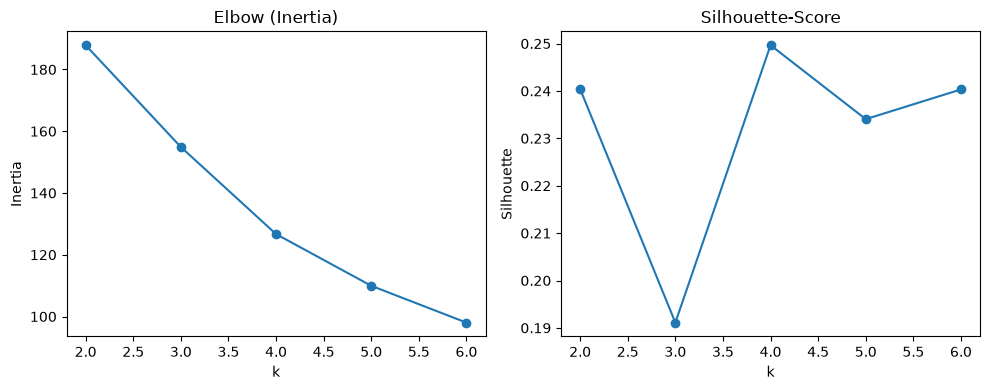

In [3]:
merkmale = ["hoehe_m", "winteranteil", "auslastung_winter", "anteil_ausland", "schnee_mittel", "betten"]
X = StandardScaler().fit_transform(profil[merkmale])

res = []
for k in range(2, 7):                                # bei 45 Orten sind mehr Gruppen nicht sinnvoll
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    res.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_)})
res = pd.DataFrame(res); print(res.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(res.k, res.inertia, "o-"); ax[0].set_title("Elbow (Inertia)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(res.k, res.silhouette, "o-"); ax[1].set_title("Silhouette-Score"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.savefig("../figures/cluster_elbow.png", dpi=150); plt.show()

In [4]:
K = 3
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
profil["cluster"] = km.labels_

profil["hoehenklasse"] = profil["bfs_nr"].map(panel.groupby("bfs_nr")["hoehenklasse"].first())
tabelle = profil.groupby("cluster")[merkmale].mean().round(2)
tabelle["n_Orte"] = profil.groupby("cluster").size()
print(tabelle)
print(profil.groupby("cluster")["name"].apply(lambda s: ", ".join(sorted(s))))
print(pd.crosstab(profil["cluster"], profil["hoehenklasse"]))

         hoehe_m  winteranteil  auslastung_winter  anteil_ausland  \
cluster                                                             
0        1114.10          0.40              36.10            0.23   
1        1278.09          0.48              56.93            0.33   
2        1657.67          0.52              65.96            0.48   

         schnee_mittel   betten  n_Orte  
cluster                                  
0                20.68   592.50      10  
1                35.03  1069.64      23  
2                46.87  3142.81      12  
cluster
0    Bregaglia, Château-d'Oex, Evolène, Glarus Süd,...
1    Adelboden, Andermatt, Breil/Brigels, Champéry,...
2    Anniviers, Arosa, Celerina/Schlarigna, Crans-M...
Name: name, dtype: str
hoehenklasse  hoch  mittel  tief
cluster                         
0                0       4     6
1                2      14     7
2               11       1     0


In [8]:
namen = {0: "Kleine Voralpenorte", 1: "Mittelgrosse Bergorte", 2: "Hochalpine Resorts"}
profil["cluster_name"] = profil["cluster"].map(namen)
profil.groupby("cluster_name").size()

cluster_name
Hochalpine Resorts       12
Kleine Voralpenorte      10
Mittelgrosse Bergorte    23
dtype: int64

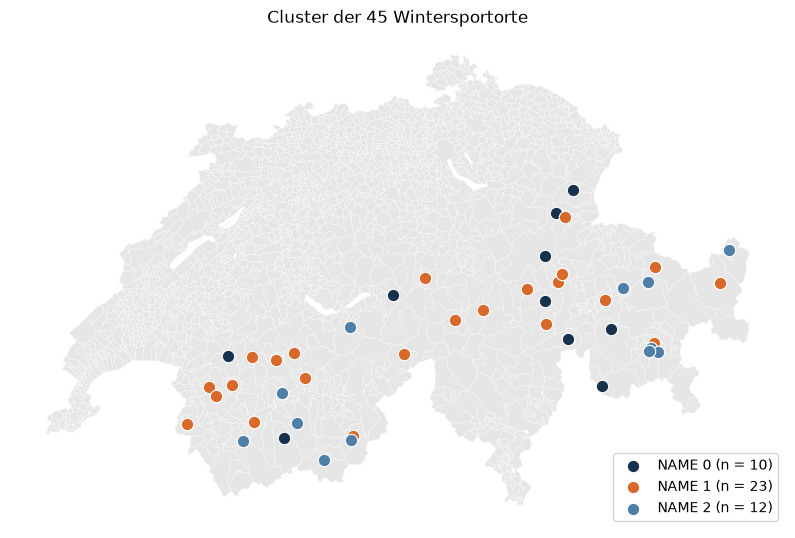

In [7]:
farben = ["#17324D", "#D9692B", "#4F7FA8", "#2E6B4F", "#8FB8D6", "#6B7A88"]
pos = panel.groupby("bfs_nr")[["lat", "lon"]].first().reset_index()
punkte = profil.merge(pos, on="bfs_nr")

fig, ax = plt.subplots(figsize=(10, 7))
try:
    import geopandas as gpd
    geo = gpd.read_file("../data/processed/gemeinden.geojson").to_crs(4326)
    geo.plot(ax=ax, color="#e6e6e6", edgecolor="white", linewidth=0.2)
except Exception as e:
    print("Hintergrundkarte nicht geladen:", e)
    ax.set_aspect(1 / np.cos(np.deg2rad(46.8)))
for i, (name, d) in enumerate(punkte.groupby("cluster_name")):
    ax.scatter(d["lon"], d["lat"], s=80, color=farben[i], edgecolor="white", linewidth=0.8, label=f"{name} (n = {len(d)})")
ax.legend(loc="lower right"); ax.set_axis_off(); ax.set_title("Cluster der 45 Wintersportorte")
fig.savefig("../figures/cluster_karte.png", dpi=200, bbox_inches="tight")

### Fazit Clustering
- Gewählt: k = 3. Der Silhouette-Score ist bei allen k niedrig (0.19 bis 0.25), die Elbow-Kurve hat keinen klaren Knick. Die Orte bilden eher ein Gefälle als klar getrennte Gruppen. k = 3 wurde wegen der Beschreibbarkeit gewählt.
- Kleine Voralpenorte (n = 10): niedrig gelegen (1114 m), Auslastung 36 %, kleine Betriebe (593 Betten).
- Mittelgrosse Bergorte (n = 23): 1278 m, Auslastung 57 %, Ausländeranteil 33 %.
- Hochalpine Resorts (n = 12): 1658 m, Auslastung 66 %, Ausländeranteil 48 %, grosse Betriebe (3143 Betten), 11 von 12 Orten hoch gelegen.
- Vergleich mit 5.3: Die Cluster entsprechen weitgehend den Höhenklassen und bringen wenig zusätzliche Information. Der Schnee-Effekt war in tiefen Orten tendenziell grösser (+0.41 Prozentpunkte), ein gesicherter Unterschied besteht nicht.
- Die Cluster beschreiben die Orte, sie erklären den Schnee-Effekt nicht.